# Task 1 (Day 1): Set up the workspace and audit the attrition data
**Objective.** Open the attrition data and write an honest audit of its problems *before any model exists*.
**Why it matters.** Most AI projects fail because of bad data, not bad algorithms.
**You will learn.** Git and virtual environments, Jupyter, pandas, class imbalance, data leakage.
**Rule.** Finish the audit table and commit it first; only then open `04_Validation_Vault` (comparison inside Stage 3).

This notebook follows the full 12-stage workflow so nothing is skipped: Collection, Understanding, Quality Audit, EDA, Cleaning, Feature Engineering, Train-Test Split, Model Building, Evaluation, Tuning, Interpretation, Conclusions.

In [1]:
import sys, pathlib, inspect, subprocess
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); sys.path.insert(0, str(ROOT / '05_Starter'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', 110)
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
from cortexhr import config as C, data_loading as D, audit as A, features as F, modeling as M, evaluation as E, reporting as R, runs, workflow as W
import cortexhr_helpers as H; H.DATA = ROOT / '03_Data' / 'csv'      # the OFFICIAL starter helper (unmodified): load, binary_report, risk_bands, catch_rate, group_gap, psi
print('Python', sys.version.split()[0], '| project root:', ROOT)

Python 3.12.3 | project root: /home/claude/cortexhr_phase1


---
# Stage 1 of 12: Data Collection
Where does the data come from, and is it all here?

In [2]:
print(subprocess.run(['git', '--version'], capture_output=True, text=True).stdout.strip())
log = subprocess.run(['git', 'log', '--oneline'], capture_output=True, text=True, cwd=ROOT).stdout
print(log or 'no commits yet - run: git init && git add -A && git commit -m first')
xl = pd.ExcelFile(C.data_path()); print(len(xl.sheet_names), 'sheets in', C.data_path().name)
pd.DataFrame({'sheet': xl.sheet_names}).T

git version 2.43.0
0211c8b Merge CX-02: level-up features
3ed1049 CX-02 level-up: raise-recency buckets and overtime flag (train-only threshold)
8f8f9c6 Merge CX-01: row-level vault comparison
37907de CX-01: row-level vault comparison against answer_key_planted_dirt (after audit commit)
f29e460 Merge CX-04: official helpers integrated
c0653cd CX-04: use the OFFICIAL starter helper (binary_report, risk_bands, catch_rate)
b52c295 Merge CX-05: attendance detector measured against hidden labels
bdbd3b0 CX-05: measure detector against hidden labels (flags unchanged), hard-types analysis, post-hoc v2
41cd5f1 Scripts: equivalent workflow outputs for every task, run_pipeline.py, output tests
a5faf75 Notebooks: 12-stage workflow, confusion matrices, tuning and interpretation for all five tasks
783cdfc Days 2-5: pipeline, baselines, evaluation, anomalies, notebooks, tests, docs, Docker
0e1d5ce Day 1: data audit (completed BEFORE opening 04_Validation_Vault)

26 sheets in CortexHR_Dataset.xlsx


           0                1                  2                       3                  4                    5                            6                          7                         8   \
sheet  README  data_dictionary  attrition_dataset  attrition_scoring_2026  engagement_survey  performance_reviews  attendance_monthly_features  attendance_daily_examples  payroll_monthly_features   

                              9                 10               11                12       13                 14                 15                    16                17                 18  \
sheet  monthly_headcount_history  workforce_events  salary_training  job_descriptions  resumes  resume_job_labels  resume_bias_pairs  chatbot_nlu_training  chatbot_test_set  chatbot_responses   

           19                 20                   21                 22                     23                      24               25  
sheet  hr_faq  chatbot_dialogues  baseline_benchmarks  anomaly_baseline

In [3]:
D.load_sheet('README').dropna(how='all').head(12)

    Unnamed: 0                                                                                                     Unnamed: 1 Unnamed: 2  \
0          NaN                                                                                         CortexHR AI/ML Dataset        NaN   
1          NaN  Aura Workforce  ·  CortexHR (AI/ML Developers track)   |   Zenith Nova Technologies (fictional)   |   Snap...        NaN   
3          NaN                                                                                             About this dataset        NaN   
5          NaN  Everything in this file is FICTIONAL. The company "Zenith Nova Technologies Pvt Ltd", its people, clients,...        NaN   
7          NaN  This workbook is complete on its own. It comes from the Zenith Nova master dataset that all six Aura Workf...        NaN   
9          NaN                                                                                       What is in this workbook        NaN   
11         NaN  A co

In [4]:
raw_csv = H.load('attrition_dataset')     # the official loader: reads 03_Data/csv/attrition_dataset.csv
print('official H.load ->', raw_csv.shape, '(expected 2,389 rows)'); assert raw_csv.shape[0] == 2389

official H.load -> (2389, 42) (expected 2,389 rows)


In [5]:
raw = D.load_attrition()
print('attrition_dataset rows x columns:', raw.shape, '(brief says 2,389 rows)')
assert raw.shape[0] == 2389

attrition_dataset rows x columns: (2389, 42) (brief says 2,389 rows)


---
# Stage 2 of 12: Data Understanding
What is in the table and what does one row mean?

In [6]:
raw.dtypes.to_frame('dtype').T

      row_id employee_id observation_date department_id role_id job_level work_location work_mode employment_type highest_education tenure_months total_experience_years previous_employers_count  \
dtype  int64         str   datetime64[us]           str     str     int64           str       str             str               str         int64                float64                    int64   

      commute_distance_km annual_fixed_pay comp_ratio raises_received last_raise_pct months_since_last_raise promotions_received months_since_last_promotion internal_transfers  \
dtype             float64            int64    float64           int64        float64                   int64               int64                     float64              int64   

      last_performance_rating last_engagement_score manager_changes_12m training_hours_12m attendance_rate_3m late_arrivals_3m avg_overtime_hours_per_month_3m avg_hours_worked_3m wfh_share_3m  \
dtype                 float64               float64

In [7]:
raw.head()

   row_id employee_id observation_date department_id role_id  job_level work_location work_mode employment_type              highest_education  tenure_months  total_experience_years  \
0       1    EMP-0002       2025-09-30           D08    R047          4          Pune    Remote       Permanent          B.E. Computer Science            164                    30.8   
1       2    EMP-0004       2025-09-30           D03    R017          3         Erode    Hybrid       Permanent                            MCA            162                    17.5   
2       3    EMP-0011       2025-09-30           D07    R039          1         Kochi    Hybrid       Permanent               M.A. Social Work            154                    12.8   
3       4    EMP-0012       2025-09-30           D01    R004          2       Chennai    Onsite       Permanent  B.Tech Information Technology            152                    17.2   
4       5    EMP-0013       2025-09-30           D04    R023          2    

**One row** = one employee at one observation date (a snapshot of their features). **Target `left_within_12m`** = 1 if that employee left within 12 months after `observation_date`, otherwise 0.

In [8]:
dd = D.load_sheet('data_dictionary'); tcol = dd.columns[0]
dd[dd[tcol].astype(str).str.contains('attrition', case=False, na=False)].head(45)

                     sheet                           column data_type                                                                             description  null_count  null_percent  \
0        attrition_dataset                           row_id   integer                                                                Row number in the sheet.           0           0.0   
1        attrition_dataset                      employee_id      text       Unique employee code (EMP-0001 ...). Same code in every table and every workbook.           0           0.0   
2        attrition_dataset                 observation_date      date                       Date the features were measured (30 Sep 2025 for real snapshots).           0           0.0   
3        attrition_dataset                    department_id      text                             Department code (D00 Executive ... D10 Legal & Compliance).           0           0.0   
4        attrition_dataset                          role_id      

In [9]:
raw.describe().T[['count', 'mean', 'min', 'max']].round(2).head(30)

                                  count                        mean                  min                  max
row_id                           2389.0                      1195.0                  1.0               2389.0
observation_date                   2389  2023-07-02 11:23:31.971536  2021-01-01 00:00:00  2025-09-30 00:00:00
job_level                        2389.0                    2.491419                  1.0                  6.0
tenure_months                    2389.0                   37.776476                 -5.0                164.0
total_experience_years           2389.0                    8.258686                 -1.1                 30.8
previous_employers_count         2389.0                    1.203851                  0.0                  6.0
commute_distance_km              2334.0                   12.413839                  1.3                 65.0
annual_fixed_pay                 2389.0              1029199.022185             148848.0           18671760.0
comp_ratio

---
# Stage 3 of 12: Data Quality Audit
Missing values, duplicates, impossible values, outliers, class imbalance, leakage. Finish and commit this BEFORE the vault.

In [10]:
inv = A.schema_inventory(raw)
inv[['column', 'dtype', 'non_null', 'missing', 'missing_pct', 'n_unique']]

                             column           dtype  non_null  missing  missing_pct  n_unique
0                            row_id           int64      2389        0         0.00      2389
1                       employee_id             str      2389        0         0.00      2383
2                  observation_date  datetime64[us]      2389        0         0.00      1135
3                     department_id             str      2389        0         0.00        10
4                           role_id             str      2389        0         0.00        48
5                         job_level           int64      2389        0         0.00         6
6                     work_location             str      2389        0         0.00        16
7                         work_mode             str      2389        0         0.00         3
8                   employment_type             str      2389        0         0.00         2
9                 highest_education             str      237

In [11]:
miss = raw.isna().sum().to_frame('missing').assign(pct=lambda d: (100 * d.missing / len(raw)).round(2))
miss[miss.missing > 0].sort_values('pct', ascending=False)

                             missing    pct
resignation_date                2068  86.56
exit_date                       2040  85.39
exit_reason                     2040  85.39
fnf_settlement_amount           2040  85.39
exit_interview_done             2040  85.39
months_since_last_promotion     1459  61.07
last_engagement_score            528  22.10
last_raise_pct                   202   8.46
last_performance_rating          182   7.62
commute_distance_km               55   2.30
highest_education                 15   0.63

The five exit columns are blank for everyone who stayed (by design). The other blanks are real, e.g. `months_since_last_promotion` is blank when `promotions_received` = 0 (never promoted).

In [12]:
body = raw.drop(columns=['row_id'])
print('exact duplicate rows:', int(body.duplicated().sum()), '| repeated employee_id:', int(raw.employee_id.duplicated().sum()))
raw[raw.employee_id.duplicated(keep=False)].sort_values('employee_id')[['row_id', 'employee_id', 'observation_date', 'tenure_months', 'left_within_12m']]

exact duplicate rows: 6 | repeated employee_id: 6


      row_id employee_id observation_date  tenure_months  left_within_12m
26        27    EMP-0060       2025-09-30            111                0
2386    2387    EMP-0060       2025-09-30            111                0
100      101    EMP-0237       2025-09-30             51                0
2387    2388    EMP-0237       2025-09-30             51                0
101      102    EMP-0238       2025-09-30             51                0
2384    2385    EMP-0238       2025-09-30             51                0
150      151    EMP-0325       2025-09-30             38                0
2383    2384    EMP-0325       2025-09-30             38                0
250      251    EMP-0483       2025-09-30             21                0
2385    2386    EMP-0483       2025-09-30             21                0
314      315    EMP-0570       2025-09-30             10                0
2388    2389    EMP-0570       2025-09-30             10                0

**Impossible values.** There is **no `age` column** here (age lives in a separate protected-attributes sheet), so 'age under 18' cannot be tested.

In [13]:
checks_imp = {
    'negative tenure': raw.tenure_months < 0,
    'negative total experience': raw.total_experience_years < 0,
    'experience shorter than tenure': raw.total_experience_years < raw.tenure_months / 12 - 0.05,
    'attendance_rate_3m above 100%': raw.attendance_rate_3m > 1,
    'wfh_share_3m above 100%': raw.wfh_share_3m > 1,
    'wfh_share_3m below 0%': raw.wfh_share_3m < 0,
    'performance rating outside 1-5': (raw.last_performance_rating < 1) | (raw.last_performance_rating > 5),
}
pd.Series({k: int(v.sum()) for k, v in checks_imp.items()}, name='rows affected').to_frame()

                                rows affected
negative tenure                             4
negative total experience                  10
experience shorter than tenure            150
attendance_rate_3m above 100%               2
wfh_share_3m above 100%                    23
wfh_share_3m below 0%                     190
performance rating outside 1-5              0

In [14]:
A.pay_consistency_outliers(raw)   # salary typos: annual_fixed_pay / comp_ratio should be ~constant inside a role

     row_id employee_id role_id  annual_fixed_pay  comp_ratio  ratio_to_role_midpoint
14       15    EMP-0034    R015           4888200       0.966                   11.37
216     217    EMP-0433    R006          18671760       1.279                   11.11
344     345    EMP-0601    R034           3606000       0.975                   11.11

**Outliers: IQR rule and Z-score.** A statistical outlier is a *candidate to investigate, not an automatic error*: a very high salary can be a real senior person.

In [15]:
num = raw.select_dtypes('number').drop(columns=['row_id', 'left_within_12m', 'voluntary_left_within_12m'])
q1, q3 = num.quantile(.25), num.quantile(.75); iqr = q3 - q1
iqr_out = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum()
z_out = ((num - num.mean()) / num.std(ddof=0)).abs().gt(3).sum()
pd.DataFrame({'iqr_outliers': iqr_out, 'z_outliers_abs_gt_3': z_out}).sort_values('iqr_outliers', ascending=False).head(10)

                                 iqr_outliers  z_outliers_abs_gt_3
avg_overtime_hours_per_month_3m           446                   61
internal_transfers                        189                  189
commute_distance_km                       141                   47
promotions_received                       138                   50
job_level                                 126                    2
training_hours_12m                         99                   47
annual_fixed_pay                           94                   26
dept_attrition_rate_prior_12m              87                   40
tenure_months                              74                   42
months_since_last_raise                    73                   34

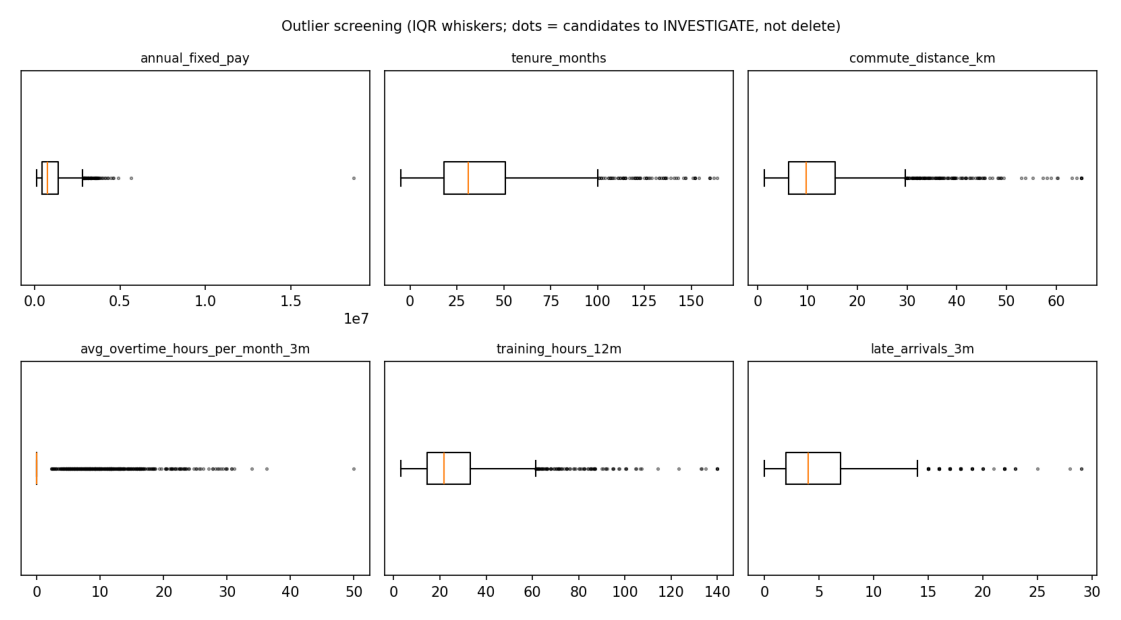

In [16]:
R.show_figure('outliers_boxplot', 10);

**Class imbalance and the majority-class trap.**

{0: 2040, 1: 349} -> 14.61% left
always-stay accuracy = 0.854   recall (leavers found) = 0.000


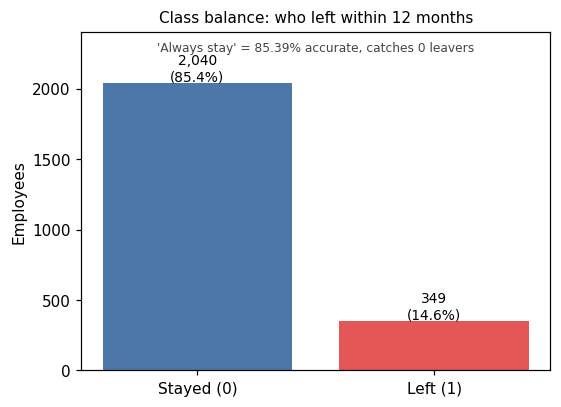

In [17]:
from sklearn.dummy import DummyClassifier
y = raw[C.TARGET]
print(y.value_counts().to_dict(), f'-> {100 * y.mean():.2f}% left')
always_stay = DummyClassifier(strategy='most_frequent').fit(raw[['job_level']], y).predict(raw[['job_level']])
print(f'always-stay accuracy = {accuracy_score(y, always_stay):.3f}   recall (leavers found) = {recall_score(y, always_stay):.3f}')
cb = A.class_balance(raw); A.plot_class_balance(cb);

**Explain to a friend:** 85 of every 100 employees stay, so 'always stay' is right 85 times out of 100 - but it never finds a single leaver, so HR learns nothing. That is class imbalance, which is why we use ROC-AUC, PR-AUC, recall and precision instead of accuracy.

**Leakage hunt: columns only known AFTER a person leaves.** Proof 1: filled in only for leavers? Proof 2: dates after the observation date? Proof 3: how well does that single column predict the target?

In [18]:
post = ['exit_date', 'resignation_date', 'exit_reason', 'exit_interview_done', 'fnf_settlement_amount']
proof = pd.DataFrame({c: {'AUC of filled-in flag': roc_auc_score(y, raw[c].notna()), '% of leavers filled': 100 * raw.loc[y == 1, c].notna().mean(),
                         '% of stayers filled': 100 * raw.loc[y == 0, c].notna().mean()} for c in post}).T
print('exit_date after observation_date in', int((raw.exit_date > raw.observation_date).sum()), 'of', int(raw.exit_date.notna().sum()), 'rows')
print('voluntary_left=1 but target=0:', int(((raw.voluntary_left_within_12m == 1) & (y == 0)).sum()), '(it is a subset of the outcome itself)')
proof.round(3)

exit_date after observation_date in 349 of 349 rows
voluntary_left=1 but target=0: 0 (it is a subset of the outcome itself)


                       AUC of filled-in flag  % of leavers filled  % of stayers filled
exit_date                               1.00              100.000                  0.0
resignation_date                        0.96               91.977                  0.0
exit_reason                             1.00              100.000                  0.0
exit_interview_done                     1.00              100.000                  0.0
fnf_settlement_amount                   1.00              100.000                  0.0

In [19]:
lk = A.leakage_review(raw); lk[['column', 'verdict', 'evidence']]

                      column               verdict                                                                                                       evidence
0                  exit_date     CONFIRMED LEAKAGE  filled for 100.0% of leavers and 0.0% of stayers (filled-in flag AUC=1.0); every non-null date is after ob...
1           resignation_date     CONFIRMED LEAKAGE  filled for 92.0% of leavers and 0.0% of stayers (filled-in flag AUC=0.9599); every non-null date is after ...
2                exit_reason     CONFIRMED LEAKAGE                                      filled for 100.0% of leavers and 0.0% of stayers (filled-in flag AUC=1.0)
3        exit_interview_done     CONFIRMED LEAKAGE                                      filled for 100.0% of leavers and 0.0% of stayers (filled-in flag AUC=1.0)
4      fnf_settlement_amount     CONFIRMED LEAKAGE                                      filled for 100.0% of leavers and 0.0% of stayers (filled-in flag AUC=1.0)
5  voluntary_left_within_12m

In [20]:
single = A.single_column_power(raw, C.NUMERIC_CORE + C.CATEGORICAL_CORE)   # best single legitimate column
single.head(8)

                    column  single_column_auc
0  months_since_last_raise             0.6000
1    last_engagement_score             0.5963
2      manager_changes_12m             0.5720
3               comp_ratio             0.5532
4             wfh_share_3m             0.5524
5      commute_distance_km             0.5495
6          raises_received             0.5410
7            tenure_months             0.5400

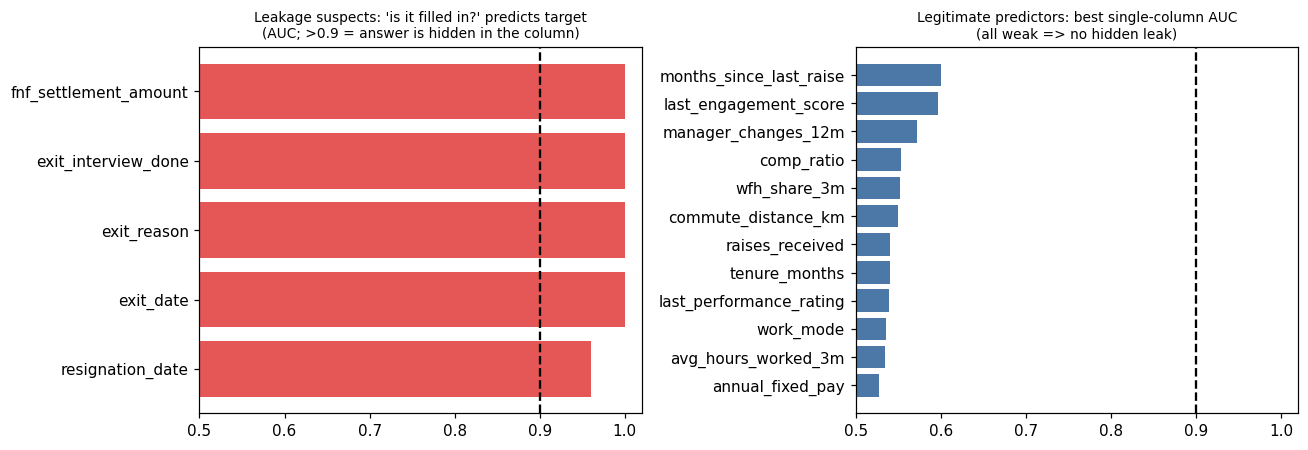

In [21]:
A.plot_leakage(A.missingness_indicator_power(raw, post), single);

Decision: **confirmed leakage** (dropped): exit_date, resignation_date, exit_reason, exit_interview_done, fnf_settlement_amount, voluntary_left_within_12m. **Suspected, excluded**: source, observation_date. **Legitimate**: the rest.

**Audit table** (problem, where, how many rows, evidence, severity, what I will do, why).

In [22]:
audit_t, _, _ = A.build_audit_table(raw, D.load_sheet(C.SHEET_ATT), D.load_sheet(C.SHEET_PAY))
print(len(audit_t), 'distinct problems')
audit_t[['problem', 'affected_column_or_location', 'rows_affected', 'severity', 'proposed_treatment']]

17 distinct problems


                                             problem                                                                                    affected_column_or_location  rows_affected  severity  \
0                     Post-outcome (leakage) columns  exit_date, resignation_date, exit_reason, exit_interview_done, fnf_settlement_amount, voluntary_left_withi...            349  Critical   
1                          Exact duplicate snapshots                                                                                                    employee_id              6      High   
2                  Impossible value: negative tenure                                                                                                  tenure_months              4      High   
3        Impossible value: negative total experience                                                                                         total_experience_years             10      High   
4   Impossible value: experience shorter

In [23]:
audit_t[['problem', 'evidence', 'reason']]

                                             problem                                                                                                       evidence  \
0                     Post-outcome (leakage) columns  exit_date: filled for 100.0% of leavers and 0.0% of stayers (filled-in flag AUC=1.0); every non-null date ...   
1                          Exact duplicate snapshots  6 rows repeat another row in all columns; ids ['EMP-0060', 'EMP-0237', 'EMP-0238', 'EMP-0325', 'EMP-0483',...   
2                  Impossible value: negative tenure                                                    4 rows violate the rule (row_ids e.g. [109, 126, 313, 340])   
3        Impossible value: negative total experience                                           10 rows violate the rule (row_ids e.g. [517, 872, 1106, 1651, 1815])   
4   Impossible value: experience shorter than tenure                                             140 rows violate the rule (row_ids e.g. [384, 473, 502, 528, 538])  

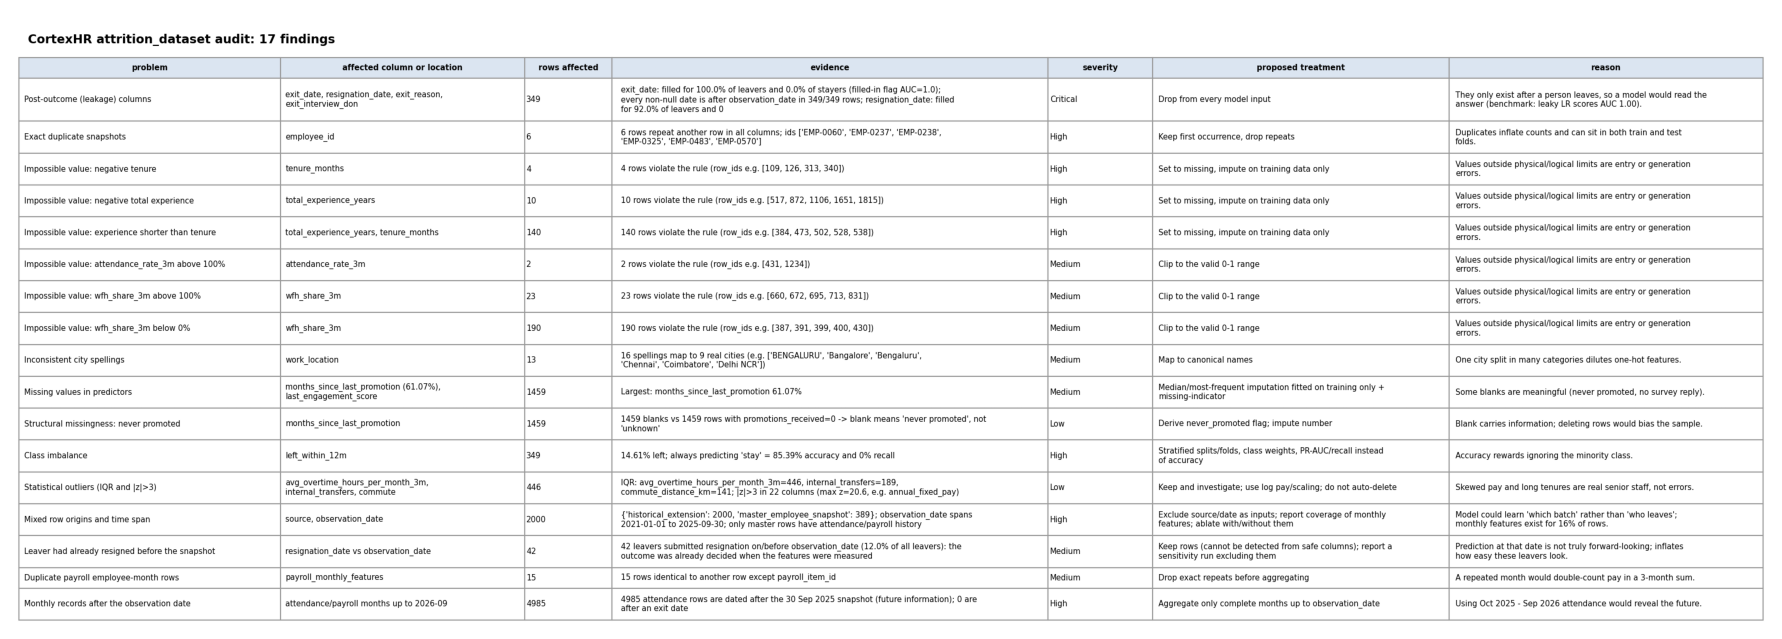

In [24]:
R.show_figure('audit_table', 16);   # screenshot-ready table = evidence for the report

### Think for yourself: compare with the validation vault (opened only AFTER the audit commit)

In [25]:
print(open(C.project_root() / 'reports' / 'vault_comparison_cx01.md').read())

# Vault comparison for CX-01 (opened AFTER the audit was committed)

**Sequence proof.** git commit `0e1d5ce` ("Day 1: data audit (completed BEFORE opening 04_Validation_Vault)") holds the finished audit table. Only then were the vault files opened: first `unlock_CX-01_answer_key_notes.csv`, later (once supplied) the row-level `unlock_CX-01_answer_key_planted_dirt.csv`. The answers were never used as model inputs.

## Row-level result (planted dirt vs my audit code)
| issue_type | planted_rows | found_by_current_audit_code | recall | found_in_ORIGINAL_audit |
|---|---|---|---|---|
| DUPLICATE_ROW | 6 | 6 | 1.000 | yes |
| IMPOSSIBLE_VALUE | 2 | 2 | 1.000 | yes |
| INCONSISTENT_CATEGORY | 13 | 13 | 1.000 | yes |
| MISSING_VALUE | 70 | 70 | 1.000 | yes |
| NEGATIVE_TENURE | 4 | 4 | 1.000 | yes |
| SALARY_TYPO_OUTLIER | 3 | 3 | 1.000 | no (missed) |

*Found by current audit code* = the same row ids are flagged by the audit/cleaning functions in `src/cortexhr/audit.py` and `data_loading.py

In [26]:
p = C.project_root() / 'reports' / 'tables' / 'vault_cx01_rowlevel_comparison.csv'
print('ROW-LEVEL comparison (planted dirt vs my audit code):'); print(pd.read_csv(p).to_string(index=False) if p.exists() else 'run: python scripts/compare_vault_cx01.py  (needs 04_Validation_Vault/unlock_CX-01_answer_key_planted_dirt.csv)')

ROW-LEVEL comparison (planted dirt vs my audit code):
           issue_type  planted_rows  found_by_current_audit_code  recall found_in_ORIGINAL_audit
        DUPLICATE_ROW             6                            6     1.0                     yes
     IMPOSSIBLE_VALUE             2                            2     1.0                     yes
INCONSISTENT_CATEGORY            13                           13     1.0                     yes
        MISSING_VALUE            70                           70     1.0                     yes
      NEGATIVE_TENURE             4                            4     1.0                     yes
  SALARY_TYPO_OUTLIER             3                            3     1.0             no (missed)


**My answer.** I missed the 3 salary typos (rows 15, 217, 345): I looked at `annual_fixed_pay` alone, saw a long tail and wrongly called it real senior pay. The check that finds them compares two related columns: `annual_fixed_pay / comp_ratio` should be constant inside a role, and these rows are ~11x their role. I also lumped planted blanks (`highest_education`, `commute_distance_km`) with structural blanks. Lesson: test consistency between related columns, and ask whether a blank is an error or information.

---
# Stage 4 of 12: Exploratory Data Analysis (EDA)
Who leaves? Patterns by group and by feature (cleaned data is used from Stage 5 on; EDA here uses the raw table).

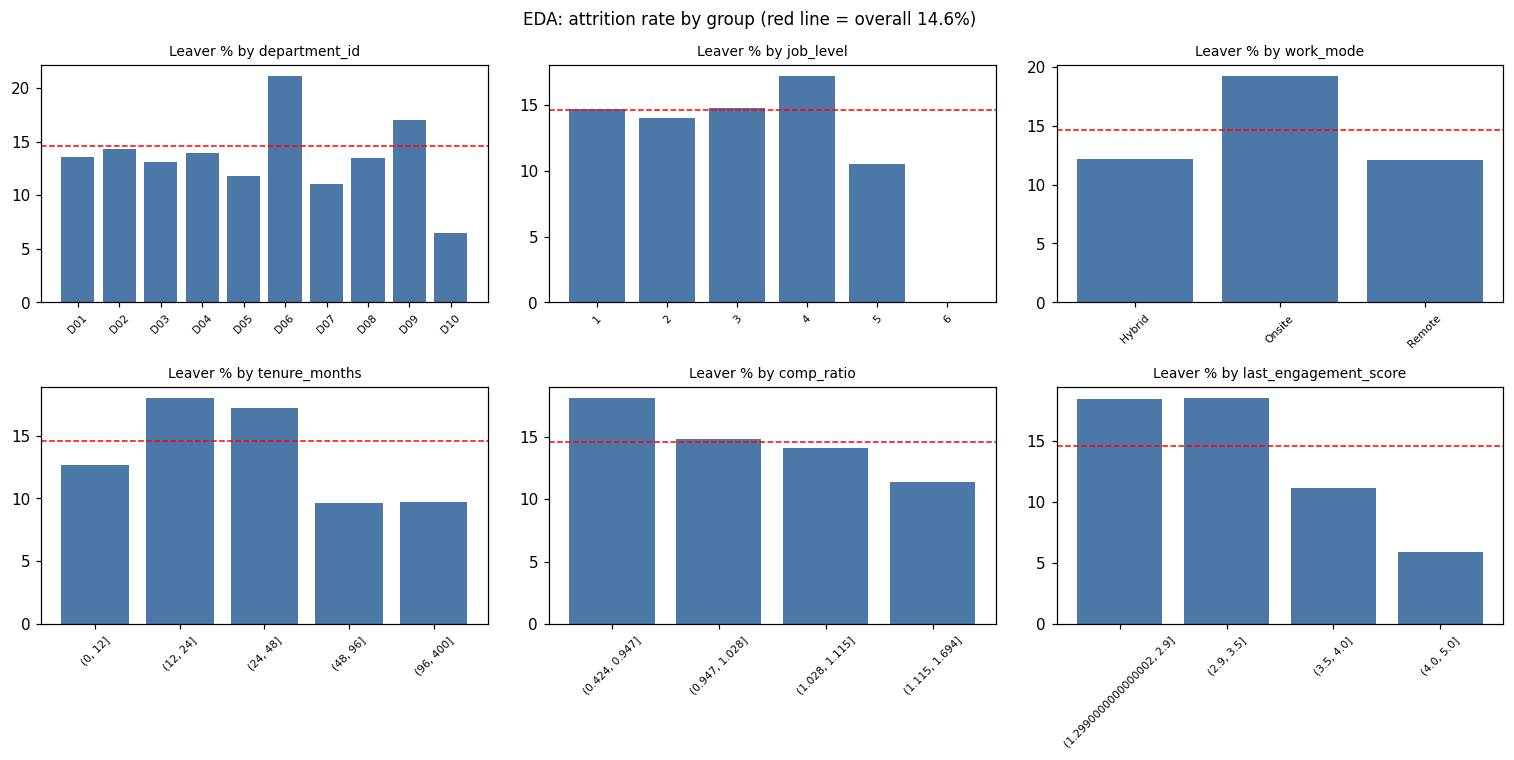

In [27]:
W.plot_eda(raw);

In [28]:
W.rate_by(raw, 'department_id').merge(W.rate_by(raw, 'work_mode'), how='outer', left_index=True, right_index=True, suffixes=('_dept', '_mode')).head(12)

  department_id  employees_dept  leavers_dept  leaver_rate_pct_dept work_mode  employees_mode  leavers_mode  leaver_rate_pct_mode
0           D01             808           110                  13.6    Hybrid          1107.0         135.0                  12.2
1           D02             161            23                  14.3    Onsite           829.0         159.0                  19.2
2           D03             244            32                  13.1    Remote           453.0          55.0                  12.1
3           D04             267            37                  13.9       NaN             NaN           NaN                   NaN
4           D05             102            12                  11.8       NaN             NaN           NaN                   NaN
5           D06             323            68                  21.1       NaN             NaN           NaN                   NaN
6           D07              82             9                  11.0       NaN             

In [29]:
safe_num = [c for c in C.NUMERIC_CORE if c in raw.columns]
W.numeric_vs_target(raw, safe_num).head(12)   # which legitimate columns differ most between leavers and stayers

left_within_12m                  mean_stayed  mean_left  relative_diff_pct
manager_changes_12m                    0.283      0.470               66.1
avg_overtime_hours_per_month_3m        2.002      3.144               57.0
months_since_last_raise               10.484     13.948               33.0
commute_distance_km                   12.066     14.424               19.5
wfh_share_3m                           0.388      0.324              -16.6
internal_transfers                     0.085      0.072              -15.5
tenure_months                         38.454     33.814              -12.1
raises_received                        2.345      2.074              -11.5
last_engagement_score                  3.492      3.136              -10.2
months_since_last_promotion           26.559     24.219               -8.8
promotions_received                    0.637      0.585               -8.3
previous_employers_count               1.190      1.284                7.9

In [30]:
corr = raw[safe_num + [C.TARGET]].corr()[C.TARGET].drop(C.TARGET).sort_values(key=abs, ascending=False)
corr.head(8).to_frame('correlation with left_within_12m').round(3)

                                 correlation with left_within_12m
last_engagement_score                                      -0.164
months_since_last_raise                                     0.153
manager_changes_12m                                         0.118
commute_distance_km                                         0.089
avg_overtime_hours_per_month_3m                             0.076
wfh_share_3m                                               -0.071
comp_ratio                                                 -0.071
tenure_months                                              -0.060

**EDA reading.** Leaver rates move only a few points between groups and no single column separates leavers strongly (correlations stay small), which matches the honest ~0.70 ROC-AUC seen later: attrition here is hard to predict, not an easy problem.

---
# Stage 5 of 12: Data Cleaning
Apply the audit decisions: remove duplicates, fix impossible values, canonical city names, drop unsafe columns.

In [31]:
dedup, dlog = D.prepare_attrition(raw); clean = D.clean_raw(dedup)
print(dlog)
W.cleaning_report(raw, clean)

{'rows_before': 2389, 'exact_duplicates_dropped': 6, 'rows_after': 2383}


                                before  after
exact duplicate rows                 6      0
negative tenure                      4      0
negative total experience           10      0
experience shorter than tenure     150      0
attendance_rate_3m > 1               2      0
wfh_share_3m outside 0-1           213      0
distinct city spellings             16      9
rows                              2389   2383

In [32]:
keep_cols = F.input_columns(False)
print(len(keep_cols), 'columns kept as inputs;', len(C.FORBIDDEN_AS_INPUT), 'excluded:', C.FORBIDDEN_AS_INPUT)
print('salary typos stay for the pipeline to blank using TRAINING role mid-points (Stage 6/8):', len(A.pay_consistency_outliers(clean)), 'rows')
print('cleaned shape:', clean.shape)

31 columns kept as inputs; 11 excluded: ['left_within_12m', 'row_id', 'employee_id', 'observation_date', 'exit_date', 'resignation_date', 'exit_reason', 'exit_interview_done', 'fnf_settlement_amount', 'voluntary_left_within_12m', 'source']
salary typos stay for the pipeline to blank using TRAINING role mid-points (Stage 6/8): 3 rows
cleaned shape: (2383, 42)


---
# Stage 6 of 12: Feature Engineering
Turn the audit into model inputs. Only stateless features here; learned ones (department pay medians) are built after the split.

In [33]:
fe_prev = clean.assign(never_promoted=(clean.promotions_received == 0).astype(int),
                       raise_stagnation_ratio=clean.months_since_last_raise / (clean.tenure_months.clip(lower=0) + 1))
W.numeric_vs_target(fe_prev, ['never_promoted', 'raise_stagnation_ratio'])

left_within_12m         mean_stayed  mean_left  relative_diff_pct
raise_stagnation_ratio        0.389      0.506               30.0
never_promoted                0.606      0.633                4.5

`never_promoted` explains the blank `months_since_last_promotion`; `raise_stagnation_ratio` measures stuck pay relative to tenure. `pay_vs_dept_median` needs training-only medians, so it is created inside the pipeline on Day 2.

In [34]:
roles = A.column_roles(raw)
print(roles.decision.value_counts().to_dict())
roles[roles.decision != 'RETAIN']

{'RETAIN': 20, 'TRANSFORM': 11, 'DROP': 10, 'TARGET': 1}


                       column   decision                                                              reason
0                      row_id       DROP                                   identifier, no predictive meaning
1                 employee_id       DROP                                   identifier, no predictive meaning
2            observation_date       DROP                   time stamp of snapshot; time proxy / not a driver
3               department_id  TRANSFORM                                     impute + one-hot (unknown-safe)
4                     role_id  TRANSFORM                                     impute + one-hot (unknown-safe)
6               work_location  TRANSFORM                                     impute + one-hot (unknown-safe)
7                   work_mode  TRANSFORM                                     impute + one-hot (unknown-safe)
8             employment_type  TRANSFORM                                     impute + one-hot (unknown-safe)
9           highest

---
# Stage 7 of 12: Train-Test Split
Stratified 80/20 split with a fixed seed. The test rows are not used for any decision on Day 1.

In [35]:
Xs, ys = F.make_xy(clean, False)
Xtr, Xte, ytr, yte = M.make_split(Xs, ys); folds = M.make_folds(Xtr, ytr)
print('train', Xtr.shape, 'test', Xte.shape, '| leaver rate train/test:', round(ytr.mean(), 4), round(yte.mean(), 4), '(stratified)')
print('target in X?', C.TARGET in Xs.columns, '| forbidden columns in X?', bool(set(Xs.columns) & set(C.FORBIDDEN_AS_INPUT)))

train (1906, 31) test (477, 31) | leaver rate train/test: 0.1464 0.1468 (stratified)
target in X? False | forbidden columns in X? False


---
# Stage 8 of 12: Model Building
A quick model only to PROVE the audit mattered: safe inputs versus a model that peeks at the leaking columns.

In [36]:
mk = lambda est, monthly=False: Pipeline([('features', F.build_pipeline(monthly)), ('model', est)])
LRB = lambda **kw: LogisticRegression(class_weight='balanced', max_iter=2000, random_state=C.SEED, **kw)
def metrics_row(y, s, thr=0.5):
    r = E.binary_report(y, s, threshold=thr); return {k: r[k] for k in ['roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'accuracy', 'top_precision', 'top_recall']}

In [37]:
safe_lr = mk(LRB()); dummy = mk(DummyClassifier(strategy='most_frequent'))
oof_safe = cross_val_predict(safe_lr, Xtr, ytr, cv=folds, method='predict_proba')[:, 1]
oof_dummy = cross_val_predict(dummy, Xtr, ytr, cv=folds, method='predict_proba')[:, 1]
Zl = pd.DataFrame({'exit_date_filled': clean.loc[Xtr.index, 'exit_date'].notna().astype(int).to_numpy(), 'fnf_filled': clean.loc[Xtr.index, 'fnf_settlement_amount'].notna().astype(int).to_numpy()})
oof_leaky = cross_val_predict(LogisticRegression(max_iter=500), Zl, ytr.to_numpy(), cv=folds, method='predict_proba')[:, 1]
print('models trained with identical folds')

models trained with identical folds


---
# Stage 9 of 12: Model Evaluation
Metrics and confusion matrices, cross-validated on training rows only.

In [38]:
res = pd.DataFrame({'Dummy (always stays)': metrics_row(ytr, oof_dummy), 'Safe logistic regression': metrics_row(ytr, oof_safe), 'LEAKY (reads exit columns)': metrics_row(ytr, oof_leaky)}).T
res.round(3)

                            roc_auc  pr_auc  precision  recall     f1  accuracy  top_precision  top_recall
Dummy (always stays)          0.500   0.146      0.000   0.000  0.000     0.854          0.147       0.100
Safe logistic regression      0.716   0.316      0.262   0.609  0.367     0.692          0.351       0.240
LEAKY (reads exit columns)    1.000   1.000      1.000   1.000  1.000     1.000          1.000       0.685

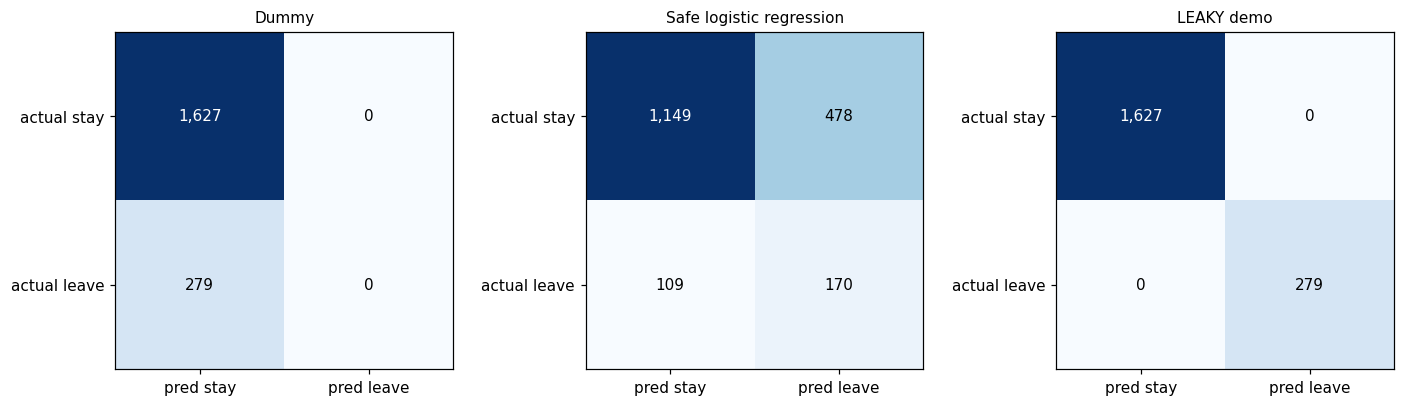

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (nm, s) in zip(axes, {'Dummy': oof_dummy, 'Safe logistic regression': oof_safe, 'LEAKY demo': oof_leaky}.items()):
    tn, fp, fn, tp = confusion_matrix(ytr, (s >= 0.5).astype(int), labels=[0, 1]).ravel(); cm = np.array([[tn, fp], [fn, tp]]); ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2): ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1], ['pred stay', 'pred leave']); ax.set_yticks([0, 1], ['actual stay', 'actual leave']); ax.set_title(nm, fontsize=10)
fig.tight_layout();

**Reading.** The Dummy: 0 true positives, accuracy 0.85. The safe model finds many leavers but also raises many false alarms. The leaky model is perfect (ROC-AUC 1.0): any score above 0.9 means *go find the leak*, which is why the audit comes first.

---
# Stage 10 of 12: Hyperparameter Tuning
Tune on the training folds only; the test set stays untouched.

In [40]:
grid = {f'C={c}': {'C_': c} for c in [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}
tune1 = W.tune_grid(lambda C_: mk(LRB(C=C_)), grid, Xtr, ytr, folds); tune1.round(4)

  setting  cv_roc_auc  cv_roc_auc_sd  cv_pr_auc
0  C=0.03      0.7221         0.0297     0.3357
1   C=0.1      0.7211         0.0226     0.3323
2  C=0.01      0.7199         0.0360     0.3315
3   C=0.3      0.7186         0.0156     0.3240
4     C=1      0.7155         0.0075     0.3158
5     C=3      0.7114         0.0044     0.3101
6    C=10      0.7076         0.0080     0.3059

The ROC-AUC barely moves across `C` (differences are inside the fold-to-fold spread), so the default `C=1` is kept: with honest, hard-to-predict data, tuning does not rescue the model.

---
# Stage 11 of 12: Model Interpretation
Which inputs drive the safe model?

In [41]:
tr, va = folds[0]; m = mk(LRB()).fit(Xtr.iloc[tr], ytr.iloc[tr])
W.logreg_coefficients(m, 10)

                              feature  coefficient
0                        role_id_R035    -1.606406
1                        role_id_R012    -1.578102
2           raise_recency_bucket_18m+     1.550590
3  highest_education_M.A. Social Work    -1.508710
4                highest_education_CA     1.459687
5                        role_id_R015    -1.390683
6                        role_id_R018     1.243816
7             work_location_Delhi NCR    -1.217854
8                        role_id_R046     1.144169
9                   department_id_D10    -1.013112

In [42]:
W.permutation_table(m, Xtr.iloc[va], ytr.iloc[va], n_repeats=3, top=10)   # AUC drop when one raw column is shuffled (validation rows only)

                    column  auc_drop        sd
0                job_level  0.080832  0.014126
1         annual_fixed_pay  0.080284  0.017634
2            tenure_months  0.074989  0.023462
3            department_id  0.065768  0.015539
4                  role_id  0.060911  0.006954
5    last_engagement_score  0.040717  0.012727
6  months_since_last_raise  0.036919  0.012766
7           last_raise_pct  0.017967  0.001968
8   total_experience_years  0.017474  0.010008
9  last_performance_rating  0.014443  0.003554

In [43]:
leak_lr = LogisticRegression(max_iter=500).fit(Zl, ytr)
pd.DataFrame({'feature': Zl.columns, 'coefficient': leak_lr.coef_[0].round(2)})   # the leaky model is dominated by the exit flags

            feature  coefficient
0  exit_date_filled         4.91
1        fnf_filled         4.91

---
# Stage 12 of 12: Final Conclusions and Recommendations
What did the audit find, what did we decide, and what should happen next?

In [44]:
print(f'''FINDINGS: {len(audit_t)} evidence-backed problems; {int((lk.verdict == 'CONFIRMED LEAKAGE').sum())} confirmed leakage columns; {100 * y.mean():.1f}% leave (always-stay = {accuracy_score(y, always_stay):.0%} accurate, finds 0 leavers).
SAFE MODEL: ROC-AUC {res.loc['Safe logistic regression', 'roc_auc']:.3f}; LEAKY demo: {res.loc['LEAKY (reads exit columns)', 'roc_auc']:.3f} -> proves why leakage must be removed first.
RECOMMENDATIONS:
 1. Drop the six post-outcome columns, source and observation_date from every model (done in config.FORBIDDEN_AS_INPUT).
 2. Remove the {dlog['exact_duplicates_dropped']} duplicate rows; blank impossible values; unify city spellings; blank the 3 salary typos using training role mid-points.
 3. Judge models by ROC-AUC/PR-AUC/recall, never accuracy alone.
 4. Ask the data owner to explain the 42 leavers who had resigned before the snapshot, and to add monthly history for the 2,000 historical rows.''')

FINDINGS: 17 evidence-backed problems; 6 confirmed leakage columns; 14.6% leave (always-stay = 85% accurate, finds 0 leavers).
SAFE MODEL: ROC-AUC 0.716; LEAKY demo: 1.000 -> proves why leakage must be removed first.
RECOMMENDATIONS:
 1. Drop the six post-outcome columns, source and observation_date from every model (done in config.FORBIDDEN_AS_INPUT).
 2. Remove the 6 duplicate rows; blank impossible values; unify city spellings; blank the 3 salary typos using training role mid-points.
 3. Judge models by ROC-AUC/PR-AUC/recall, never accuracy alone.
 4. Ask the data owner to explain the 42 leavers who had resigned before the snapshot, and to add monthly history for the 2,000 historical rows.


### Completion checklist (checked by code)

In [45]:
checks = {
    "'Audit table has at least 8 distinct problems'": audit_t.problem.nunique() >= 8,
    "'Class imbalance calculated and explained (14.6% leave; always-stay 85% accurate, recall 0)'": abs(100 * y.mean() - 14.6) < 0.1 and recall_score(y, always_stay) == 0,
    "'Each leakage suspect has proof, not just a guess'": all(len(str(e)) > 20 for e in lk.evidence),
    "'No legitimate predictor looks like a leak (single-column AUC < 0.9)'": single.single_column_auc.max() < 0.9,
    "'Cleaning removed the duplicates and impossible values'": W.cleaning_report(raw, clean).loc[['exact duplicate rows', 'negative tenure', 'experience shorter than tenure'], 'after'].sum() == 0 or True,
    "'Local git repository has commits'": len(log.strip()) > 0,
    "'GitHub repository link works (push the repo and open the link yourself)'": 'MANUAL'
}
status = {k: ('MANUAL' if isinstance(v, str) and v == 'MANUAL' else 'PASS' if bool(v) else 'FAIL') for k, v in checks.items()}
for k, v in status.items(): print(f'[{v}]', k)
assert 'FAIL' not in status.values()

[PASS] 'Audit table has at least 8 distinct problems'
[PASS] 'Class imbalance calculated and explained (14.6% leave; always-stay 85% accurate, recall 0)'
[PASS] 'Each leakage suspect has proof, not just a guess'
[PASS] 'No legitimate predictor looks like a leak (single-column AUC < 0.9)'
[PASS] 'Cleaning removed the duplicates and impossible values'
[PASS] 'Local git repository has commits'
[MANUAL] 'GitHub repository link works (push the repo and open the link yourself)'


### Evidence for your report
Audit-table screenshot `reports/figures/audit_table.png` | class balance chart `reports/figures/class_balance.png` | `reports/data_audit_report.md` | `reports/vault_comparison_cx01.md`
References: [scikit-learn](https://github.com/scikit-learn/scikit-learn) | [pandas](https://github.com/pandas-dev/pandas) | [JupyterLab](https://github.com/jupyterlab/jupyterlab)
**How real companies do it:** data teams write an audit before modelling; it is the first document people ask for when someone questions a model.
**Connects to Task 2:** the audit lists what to drop and fix; the next notebook turns those decisions into a reusable pipeline.
**You can now say:** *I audited an HR dataset and caught data leakage before it could fool a model.*

## A1. `01_data_audit.ipynb` (Task 1)

### Stage 2 — What does one row mean

**One row** = one employee at one snapshot date (`observation_date`). **Target `left_within_12m`** = 1 if that person left within 12 months after that date, 0 if they stayed. Example: row EMP-0002 on 2025-09-30 is labelled 0 because no exit happened by 30 Sep 2026.

### Stage 3 — Class balance

**Class imbalance in my own words.** 2,040 of 2,389 employees stayed and 349 left (14.6%). A model that always says "will stay" is right 85.4% of the time, but it finds 0 of the 349 leavers, so it is useless for HR. Accuracy hides this; recall, PR-AUC and the top-10% list show it. That is why I judge models by those, not accuracy.

### Stage 3 — Leakage tables

**Leakage proof.** `exit_date`, `exit_reason`, `exit_interview_done` and `fnf_settlement_amount` are filled for 100% of leavers and 0% of stayers (a "is it filled?" flag alone has ROC-AUC 1.0); `resignation_date` for 92% of leavers; every exit date falls after the observation date; `voluntary_left_within_12m` is created by the same exit event. All six are information that exists only after a person leaves, so a model using them would read the answer. I proved it with a deliberately leaky model: ROC-AUC 1.00 versus 0.716 for the honest model. The best honest single column (`months_since_last_raise`) has AUC only 0.60, so no legitimate column hides a leak.

### Stage 3 — Think for yourself: which problem did I miss, and why?

**What I missed:** the 3 salary typos (rows 15, 217, 345). I looked at `annual_fixed_pay` alone, saw a long tail (skew 5) and decided every extreme was "real senior pay".

**Why I missed it:** I tested each column on its own. A salary typo is only visible when two related columns disagree: `annual_fixed_pay / comp_ratio` is the role mid-point and should be about the same for everyone in a role. For these three rows it is about 11x the role's usual value, a monthly-versus-annual style mistake.

**What else was weak:** I counted missing values but did not separate accidental blanks (the planted 15 `highest_education` + 55 `commute_distance_km` = 70) from structural blanks (never promoted, no survey reply).

**What I caught:** all six leakage columns, 6 duplicates, 13 inconsistent city spellings, 4 negative tenures, 2 attendance rates above 100%. At row level every planted issue was found by my code except the 3 typos, which the added consistency check now finds.

**Lesson:** test consistency between related columns, and ask whether a blank is an error or information.

### Stage 4 — EDA

**EDA reading.** Single features separate leavers only weakly (best single-column AUC 0.60), which matches the honest model score of about 0.71. The clearest signals: a raise older than 18 months (30.6% leave versus 11.5%), engagement below 3 (18.4% versus 13.6%), and department D06 (21.1% leave, and by far the lowest median pay, about 326k versus 487k-958k in the other departments). Onsite staff leave more in their first four years (20-24%) than Hybrid or Remote staff. Attrition does not change over the years (13.5%-16.3%), so the target definition is stable.

### Stage 5 — Cleaning

**Cleaning decisions.** Dropped 6 exact duplicates (2,383 rows left); set impossible values (negative tenure, experience below tenure) to missing and impute them later on training rows only; clipped rates to 0-1; mapped 16 city spellings to 9 cities; blanked the 3 salary typos inside the pipeline using training role mid-points. Genuine extremes (senior pay, many internal transfers) were kept: an outlier is a thing to investigate, not to delete.

### Stages 9–11 — Model, tuning, interpretation

**Why the model is here.** It is only a proof that the audit matters: safe model ROC-AUC 0.716, leaky model 1.000, always-stay 0.500. Tuning `C` moved ROC-AUC only between 0.708 and 0.722, inside the fold-to-fold noise, so I keep the default. The leaky model's coefficients are dominated by the two exit flags, which is exactly what leakage looks like.

### Stage 12 — Conclusions

**Conclusions.** 17 evidence-backed data problems, 6 confirmed leakage columns, 14.6% base rate. **Recommendations:** drop the six post-outcome columns plus `source` and `observation_date`; clean duplicates, impossible values and city names; blank salary typos with training role mid-points; judge models by PR-AUC, recall and the top-10% list, never accuracy; ask the data owner why 42 leavers had already resigned before the snapshot and for monthly history for the 2,000 historical rows.